In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'CCCA')
pth_dev = os.path.join(pth_data, 'development', 'modeling')
pth_mod = os.path.join(pth_data, 'features', 'biomart', 'modules')
# pth_out = os.path.join(pth, 'figures', 'cancer', 'CCCA')

In [3]:
adata_dev = sc.read_h5ad(os.path.join(pth_dev, 'spectrum.h5ad'))
adata = sc.read_h5ad(os.path.join(pth_in, 'malignant.h5ad'))
adata

AnnData object with n_obs × n_vars = 1406087 × 510
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

In [4]:
mod_fn = sorted(glob.glob(os.path.join(pth_mod, '*.csv')))
get_name = lambda fn: os.path.split(fn)[1].replace('.csv', '')
mod_dict = {get_name(fn) : pd.read_csv(fn) for fn in mod_fn}

# module signatures
for mod, df_mod in mod_dict.items():
    if mod != 'ref':
        print(mod)
        g = df_mod.hsapiens.copy()
        for _, df_group in adata.obs.groupby('source', observed = True):
            msk = adata.obs_names.isin(df_group.index)
            adata_group = adata[msk].copy()
            sc.tl.score_genes(adata_group,
                              gene_list = g,
                              score_name = mod,
                              ctrl_as_ref = False,
                              random_state = 1234)
            adata.obs.loc[msk, mod] = adata_group.obs[mod]

adata.obsm['X_spectrum'] = adata.obs[['late', 'early']].values

early
late


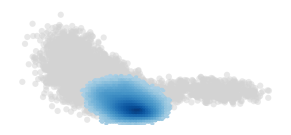

In [147]:
fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.embedding(adata_dev, 'X_spectrum', size = 80, alpha = .5,
                frameon = False, show = False, ax = ax)

xlim = ax.get_xlim()
ylim = ax.get_ylim()

bins = 100
ax.hexbin(
    adata.obs.late,
    adata.obs.early,
    extent = [*xlim, *ylim],
    gridsize = [bins, int(bins * (1.5 / 3.5))],
    mincnt = 35,
    cmap = 'Blues',
    vmin = 1,
    bins = 'log')

ax.set_xlim(xlim)
ax.set_ylim(ylim)

ax.set_title('')
plt.show()

In [6]:
# adata_dev.obs['t_bin'] = pd.cut(adata_dev.obs.t, 20, labels = False)
# crv = adata_dev.obs.groupby('t_bin', observed = True)[['late', 'early', 't']].mean()

# fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
# sc.pl.embedding(adata_dev, 'X_spectrum', size = 80, alpha = .5,
#                 frameon = False, show = False, ax = ax)
# ax.scatter(crv.late, crv.early, c = crv.t.values, cmap = 'vanimo',
#            vmin = adata_dev.obs.t.min(), vmax = adata_dev.obs.t.max())
# ax.set_title('')
# plt.show()

In [8]:
# # 
# X_crv = crv[['late', 'early']].values[np.newaxis, :, :]
# X_dev = adata_dev.obsm['X_spectrum'][:, np.newaxis, :]
# X_3ca = adata.obsm['X_spectrum'][:, np.newaxis, :]
# d_dev = np.linalg.norm(X_crv - X_dev, axis = 2)
# d_3ca = np.linalg.norm(X_crv - X_3ca, axis = 2)

# adata.obs['t'] = crv.t.values[d_3ca.argmin(axis = 1)]
# adata_dev.obs['d'] = d_dev[np.arange(d_dev.shape[0]), d_dev.argmin(axis = 1)]
# adata.obs['d'] = d_3ca[np.arange(d_3ca.shape[0]), d_3ca.argmin(axis = 1)]

# # a = .05
# # crv_plt = (adata_dev.obs.groupby('t_bin', observed = True).agg(
# #     {'t' : 'mean', 'd' : lambda d: np.quantile(d, 1 - a)}))

# # adata.obs['spectrum'] = (adata.obs.d < adata.obs.t.map(crv_plt.set_index('t').d.to_dict())).astype(str)



# # plot spectrum
# fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
# sc.pl.embedding(adata, 'X_spectrum', size = 1, alpha = .1,
#                 # color = 't', cmap = 'vanimo', colorbar_loc = None,
#                 frameon = False, show = False, ax = ax)

# sc.pl.embedding(adata_dev, 'X_spectrum', size = 120, alpha = .8,
#                 color = 't', cmap = 'vanimo', colorbar_loc = None,
#                 frameon = False, show = False, ax = ax)

# # # scf.pl.milestones(adata, basis = 'spectrum', annotate = True,
# # #                   alpha = 0, show = False, ax = ax)
# # ax.set_title('')
# # # fn = os.path.join(pth_out, 'combined.pdf')
# # # plt.savefig(fn, bbox_inches = 'tight')
# plt.show()


# # plt.plot(crv_plt.t, crv_plt.d)
# # plt.ylim(bottom = 0)
# # plt.show()

# # # msk_dist = (d <= .1).any(axis = 1)

In [ ]:
# # select developmental spectrum
# adata_dev.obs['t_bin'] = pd.cut(adata_dev.obs.t, 20, labels = False)
# X_ref = adata_dev.obs.groupby('t_bin')[['late', 'early']].mean().values[np.newaxis, :, :]
# X_3ca = adata.obsm['X_spectrum'][:, np.newaxis, :]
# d = np.linalg.norm(X_ref - X_3ca, axis = 2)
# # keep = (d <= .1).any(axis = 1)
# # keep = (X_3ca[:, 0] > X_ref[:, 0].min()) & \
# #     (X_3ca[:, 0] < X_ref[:, 0].max()) & \
# #         (X_3ca[:, 1] > X_ref[:, 1].min()) & \
# #             (X_3ca[:, 1] < X_ref[:, 1].max())

In [9]:
# for cat, sdf in adata.obs.groupby('Disease', observed = True):

#     print(cat)
#     adata_src = adata[sdf.index].copy()

#     fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
#     sc.pl.embedding(adata_dev, 'X_spectrum', size = 80, alpha = .5,
#                     frameon = False, show = False, ax = ax)

#     xlim = ax.get_xlim()
#     ylim = ax.get_ylim()

#     sc.pl.embedding(adata_src, 'X_spectrum', size = 80, alpha = .1,
#                     na_color = 'tab:blue',
#                     frameon = False, show = False, ax = ax)

#     ax.set_xlim(xlim)
#     ax.set_ylim(ylim)

#     # scf.pl.milestones(adata, basis = 'spectrum', annotate = True,
#     #                   alpha = 0, show = False, ax = ax)
#     ax.set_title('')
#     # fn = os.path.join(pth_out, f'{src}.pdf')
#     # plt.savefig(fn, bbox_inches = 'tight')
#     plt.show()